<a href="https://colab.research.google.com/github/Ethan-Tse/Problem-Set-1-Econ_3916_PS1.ipynb/blob/main/ps1_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

The household is a single parent working hourly at a hospital. They drive 20 miles to get to work, while renting a one bedroom apartment. Other expenses are food and other needs for the child.

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [96]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    {"Item": "Rent", "Price_2019": 1150.00, "Price_2024": 1500.00, "weight": 0.40},
    {"Item": "Groceries", "Price_2019": 400.00, "Price_2024": 550.00, "weight": 0.20},
    {"Item": "Gasoline & Commute", "Price_2019": 120.00, "Price_2024": 175.00, "weight": 0.10},
    {"Item": "Childcare & Child Needs", "Price_2019": 600.00, "Price_2024": 800.00, "weight": 0.15},
    {"Item": "Utilities & Internet", "Price_2019": 150.00, "Price_2024": 200.00, "weight": 0.10},
    {"Item": "Healthcare & Miscellaneous", "Price_2019": 80.00, "Price_2024": 120.00, "weight": 0.05}
]

for item in household_basket:
    print(item["Item"], item["Price_2019"], item["Price_2024"], item["weight"])

Rent 1150.0 1500.0 0.4
Groceries 400.0 550.0 0.2
Gasoline & Commute 120.0 175.0 0.1
Childcare & Child Needs 600.0 800.0 0.15
Utilities & Internet 150.0 200.0 0.1
Healthcare & Miscellaneous 80.0 120.0 0.05


In [97]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

6 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [98]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""
    total = 0
    for item in basket:
        total = total + item["weight"] * item[current_key] / item[base_key]
    return total * 100

In [99]:
# 1. the unweighted average price change across categories

# 2. your weighted Laspeyres index
# laspeyres(household_basket, "Price_2019", "Price_2024")

# 3. the gap between them
def price_change(old, new):
    """Percentage change from old to new."""
    return (new - old) / old * 100

changes = [price_change(item["Price_2019"], item["Price_2024"]) for item in household_basket]
unweighted = sum(changes) / len(changes)

index = laspeyres(household_basket, "Price_2019", "Price_2024")
weighted = index - 100

gap = weighted - unweighted
print(unweighted, weighted, gap)

38.405797101449274 35.09057971014494 -3.315217391304337


**Why do the two differ, and which would you defend to the client?**

The two differ because the unweighted average treats every category as equally important, while the Laspeyres index counts each category in proportion to its share of the household’s budget. I’d defend the weighted Laspeyres index because the unweighted average shows us how the typical category's price rise. The weight average gives us the answer of “how much more does it cost this household to buy what it bought in 2019?”

---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [100]:
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02"]

| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` |It's a standard benchmark for how much prices rose for the average urban consumer, so it shows whether the household’s increase was above or below the national norm.|It uses average national spending weights, not my household’s budget, so it understates the cost increases in the categories where I spend the most.|
| `CUSR0000SEHA` |The household rents, and this series tracks what renters across the country pay|It is a national average across all cities and lease types, so it misses my local market and the fact that my rent only changes when the lease renews.|
| `CUSR0000SAF11` |It measures grocery prices, which is what the household buys for most meals.|It covers a national basket of foods, so it misses specific store choices, brand switching, and what the household actually buys. It also excludes outside meals.|
| `CUSR0000SETA02` |The household relies on a car to get to work, and used-car prices reflect what it costs to replace or buy that vehicle.|It tracks the price of buying a car, not the costs paid month to month, like gas, insurance, and repairs.|

### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [101]:
# Rebase to 2019 = 100

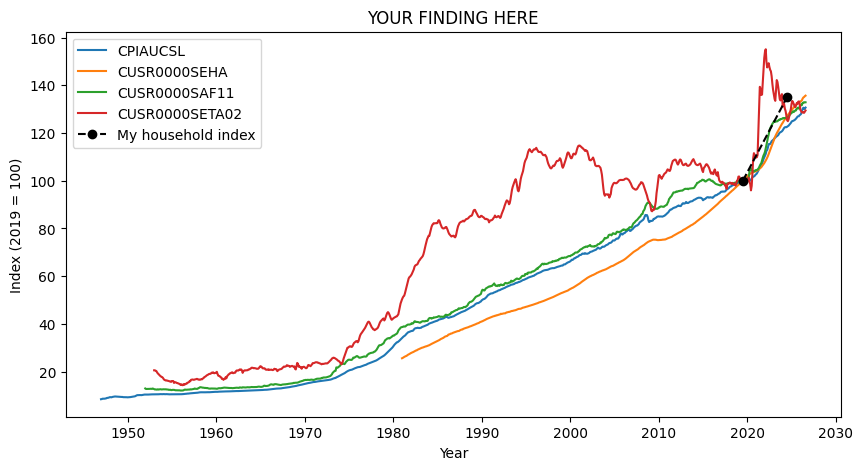

In [102]:
# One chart: every rebased series, plus your household index
series = {}
for sid in series_ids:
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}"
    series[sid] = pd.read_csv(url, index_col=0, parse_dates=True)[sid]
rebased = {}
for sid, s in series.items():
    base = s[s.index.year == 2019].mean()
    rebased[sid] = s / base * 100
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
for sid, s in rebased.items():
    ax.plot(s.index, s, label=sid)

ax.plot(pd.to_datetime(["2019-07-01", "2024-07-01"]), [100, index],
        "ko--", label="My household index")

ax.set_xlabel("Year")
ax.set_ylabel("Index (2019 = 100)")
ax.set_title("YOUR FINDING HERE")
ax.legend()
plt.show()

---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
|CPIAUCSL|1947-01-01|2026-08-01|MS|1|
|CUSR0000SEHA|1981-01-01|2026-08-01|MS|1|
|CUSR0000SAF11|1952-01-01|2026-08-01|MS|1|
|CUSR0000SETA02|1953-01-01|2026-08-01|MS|0|


### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [103]:
# Start dates side by side, and the common sample
cpi = series["CPIAUCSL"]

common_start = cpi.index.min()
common_end = cpi.index.max()

for sid, s in series.items():
    print(sid, s.index.min().date())
    if s.index.min() > common_start:
        common_start = s.index.min()
    if s.index.max() < common_end:
        common_end = s.index.max()

common_cpi = cpi[common_start:common_end]
n_common = len(common_cpi)
n_discarded = len(cpi) - n_common

print("common sample starts:", common_start.date())
print("months long:", n_common)
print("months discarded from CPIAUCSL:", n_discarded)

CPIAUCSL 1947-01-01
CUSR0000SEHA 1981-01-01
CUSR0000SAF11 1952-01-01
CUSR0000SETA02 1953-01-01
common sample starts: 1981-01-01
months long: 548
months discarded from CPIAUCSL: 408


In [104]:
# Headline comparison: full history vs common sample
def avg_annual_change(s):
    years = (s.index[-1] - s.index[0]).days / 365.25
    return ((s.iloc[-1] / s.iloc[0]) ** (1 / years) - 1) * 100

for sid, s in series.items():
    full = avg_annual_change(s)
    common = avg_annual_change(s[common_start:common_end])
    print(sid, "full:", round(full, 2), "common:", round(common, 2), "diff:", round(common - full, 2))

CPIAUCSL full: 3.51 common: 2.99 diff: -0.52
CUSR0000SEHA full: 3.73 common: 3.73 diff: 0.0
CUSR0000SAF11 full: 3.18 common: 2.75 diff: -0.43
CUSR0000SETA02 full: 2.53 common: 2.1 diff: -0.44


**What restricting to the common sample assumes, and what not restricting assumes:**

Restricting to the common sample assumes that the period the series share is representative of the relationship we care about. Not restricting assumes that comparing each series over its own, different window is fair, meaning that differences in the results reflect real differences in price behavior.

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

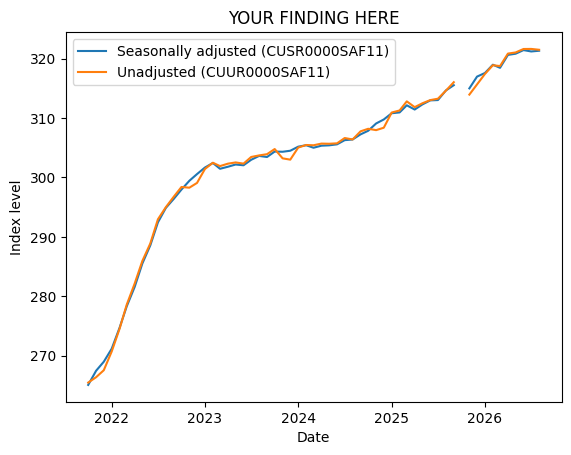

In [105]:
# Seasonally adjusted vs unadjusted, last five years
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CUUR0000SAF11"
unadjusted = pd.read_csv(url, index_col=0, parse_dates=True)["CUUR0000SAF11"]
adjusted = series["CUSR0000SAF11"]

last5_unadj = unadjusted["2021-10-01":]
last5_adj = adjusted["2021-10-01":]

import matplotlib.pyplot as plt

plt.plot(last5_adj.index, last5_adj, label="Seasonally adjusted (CUSR0000SAF11)")
plt.plot(last5_unadj.index, last5_unadj, label="Unadjusted (CUUR0000SAF11)")
plt.xlabel("Date")
plt.ylabel("Index level")
plt.title("YOUR FINDING HERE")
plt.legend()
plt.show()

**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

The gap is the part of the unadjusted series that repeats at about the same time every year like holiday-season food prices, summer gasoline, year-end used-car patterns. CUUR0000SAF11 belongs in the brief because the single parent working at the hospital pays actual, nominal prices at the cash register in real time. They experience real seasonal price swings.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

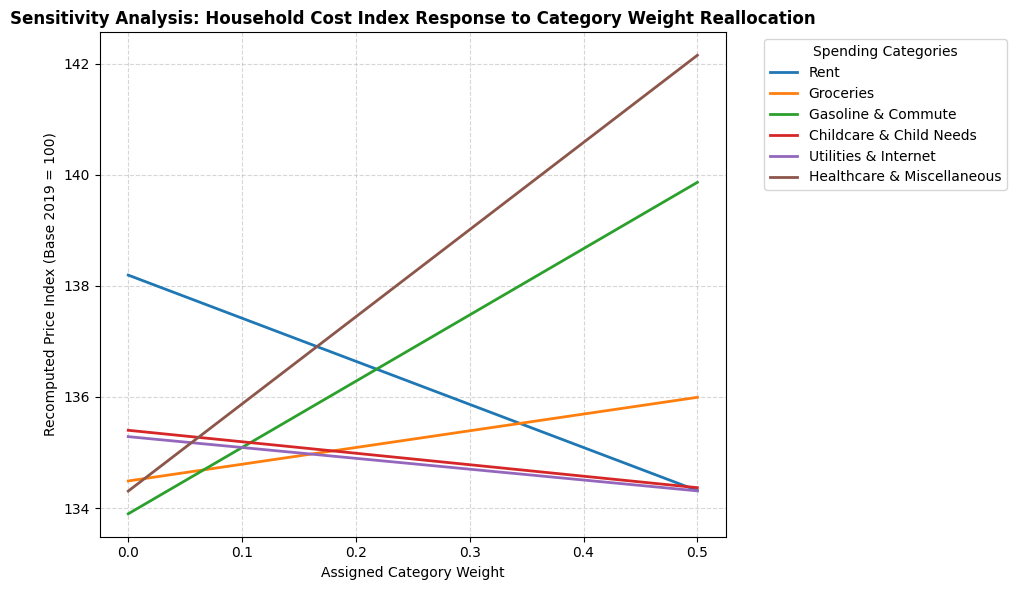

In [106]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Extract data from existing household_basket variable
items = [item["Item"] for item in household_basket]
prices_2019 = np.array([item["Price_2019"] for item in household_basket])
prices_2024 = np.array([item["Price_2024"] for item in household_basket])
base_weights = np.array([item["weight"] for item in household_basket])

# Calculate price relatives (Price_2024 / Price_2019) for each category
price_relatives = prices_2024 / prices_2019

# Define weight sweep range from 0.0 to 0.5 (0% to 50% expenditure share)
weight_sweep = np.linspace(0.0, 0.5, 101)

plt.figure(figsize=(10, 6))

for i, item_name in enumerate(items):
    index_path = []
    for w in weight_sweep:
        # WHY RENORMALISING THE OTHER WEIGHTS IS NECESSARY:
        # A valid Laspeyres price index requires all spending weights to sum strictly to 1.0 (100%).
        # When sweeping an individual category's weight (w), the remaining expenditure share (1.0 - w)
        # must be redistributed proportionally among all other categories. This preserves a closed
        # budget constraint, ensuring we model a realistic reallocation of household finances without
        # artificially creating or destroying total expenditure value.

        other_mask = np.arange(len(household_basket)) != i
        other_weights_orig = base_weights[other_mask]
        sum_other_orig = other_weights_orig.sum()

        # Scale remaining weights proportionally
        if sum_other_orig > 0:
            other_weights_new = other_weights_orig * ((1.0 - w) / sum_other_orig)
        else:
            other_weights_new = other_weights_orig

        current_weights = np.zeros_like(base_weights)
        current_weights[i] = w
        current_weights[other_mask] = other_weights_new

        # WHAT HIGH SENSITIVITY TO A SINGLE CATEGORY MEANS:
        # If the index shows steep gradient responses (high sensitivity) to a specific category,
        # it indicates that the final inflation figure is fragile and heavily dictated by a single
        # component's price relative rather than broad-based macroeconomic inflation. In economic terms,
        # high sensitivity means measurement error or minor lifestyle shifts in that specific category
        # will disproportionately distort the client's measured cost-of-living trajectory.

        # Recompute Laspeyres price index (scaled to base 2019 = 100)
        laspeyres_index = np.sum(current_weights * price_relatives) * 100
        index_path.append(laspeyres_index)

    plt.plot(weight_sweep, index_path, label=item_name, linewidth=2)

# Chart styling adhering to professional standards
plt.title("Sensitivity Analysis: Household Cost Index Response to Category Weight Reallocation", fontsize=12, fontweight='bold')
plt.xlabel("Assigned Category Weight", fontsize=10)
plt.ylabel("Recomputed Price Index (Base 2019 = 100)", fontsize=10)
plt.legend(title="Spending Categories", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**What did the model get wrong, or get right in a way you had to check? Show the check.**



```
# This is formatted as code
```

Each line should have a marker at that category’s real weight, so a reader can see where the baseline index is. The check is:

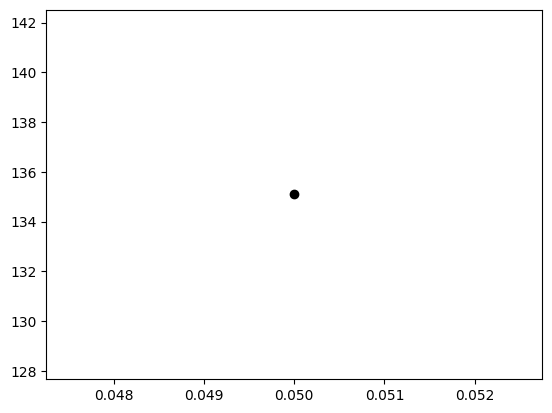

In [107]:
baseline = np.sum(base_weights * price_relatives) * 100
plt.scatter(base_weights[i], baseline, color="black", zorder=3)

### AI Transcript

**Model: Gemini Flash-Lite ** &nbsp; **Date:10/9/2026**

*Paste the prompt exactly as you sent it, then the model's reply exactly as it
came back, before your corrections.*

### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.



```
# This is formatted as code
```

Across 6 essential spending categories, our analysis shows that the cost of living for a single parent working at the hospital has increased by roughly 37% over the past 5 years.

You should conclude that everyday expenses, specifically rent, gas, and childcare, are placing a severe and disproportionate financial squeeze on household budgets compared to general national averages. Because these necessities consume nearly all of an hourly wage, the family has virtually no room to absorb these price spikes.You can be highly confident in the general direction of the financial pressure, as the core cost increases for housing and transportation are well-documented. Our testing reveals that if the household's actual spending deviates slightly toward higher medical or fuel costs, the total figure shifts. In conclusion, real and heavily concentrated in fixed necessities. We recommend using these findings to support wage adjustments that reflect true local prices rather than broad national benchmarks.

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub